In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Statistics
from scipy.stats import zscore, describe, norm
from scipy.stats import pearsonr, spearmanr, iqr

# Optimization
from scipy.optimize import minimize, least_squares

# Linear Algebra
from scipy.linalg import svd, eigh, solve

# Interpolation
from scipy.interpolate import interp1d, griddata

# Fourier Transform
from scipy.fft import fft

# Signal Processing
from scipy.signal import find_peaks

# Sparse Matrices
from scipy.sparse import csr_matrix, csc_matrix

# 1. Statistics (scipy.stats)

[-1.46385011 -0.87831007 -0.29277002  0.29277002  0.87831007  1.46385011]
DescribeResult(nobs=np.int64(6), minmax=(np.int64(10), np.int64(60)), mean=np.float64(35.0), variance=np.float64(350.0), skewness=np.float64(0.0), kurtosis=np.float64(-1.268571428571429))
0.3989422804014327


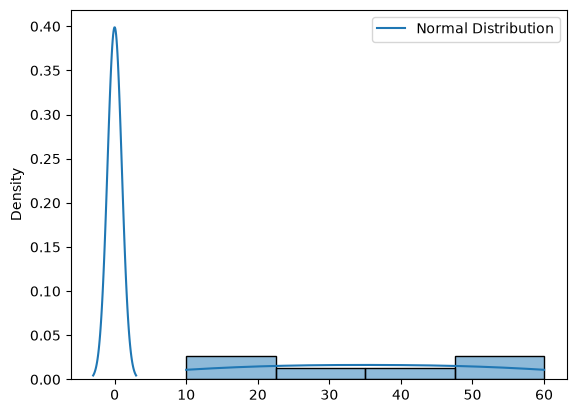

In [3]:
data = np.array([10, 20, 30, 40, 50, 60])

print(zscore(data))
print(describe(data))
print(norm.pdf(0, loc=0, scale=1))

sns.histplot(data, kde=True, stat="density")
x = np.linspace(-3, 3, 100)
plt.plot(x, norm.pdf(x), label="Normal Distribution")
plt.legend()
plt.show()

---
# 2. Correlation (scipy.stats)

PearsonRResult(statistic=np.float64(0.9537801338439742), pvalue=np.float64(0.0031550448451901614))
SignificanceResult(statistic=np.float64(1.0), pvalue=np.float64(0.0))
5.75


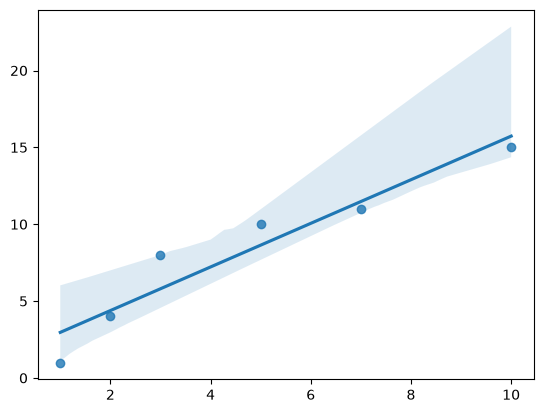

In [4]:
x = np.array([1, 2, 3, 5, 7, 10])
y = np.array([1, 4, 8, 10, 11, 15])

print(pearsonr(x, y))
print(spearmanr(x, y))
print(iqr(y))

sns.regplot(x=x, y=y)
plt.show()

---
# 3. Optimization (scipy.optimize)

In [5]:
result = minimize(lambda x: (x[0] - 5)**2, x0=[1], bounds=[(0, 3)])

print(result.x)
print(result.fun)

[3.]
4.0


In [6]:
result = least_squares(lambda x: x**2 - 25, x0=[4])

print(result.x)
print(result.cost)

[5.]
2.5243548967072378e-27


---
# 4. Linear Algebra (scipy.linalg)

In [7]:
A = np.array([[4, 1], [1, 3]])
b = np.array([9, 8])

U, S, Vt = svd(A)
print(S)

values, vectors = eigh(A)
print(values)
print(vectors)

print(solve(A, b))

[4.61803399 2.38196601]
[2.38196601 4.61803399]
[[ 0.52573111 -0.85065081]
 [-0.85065081 -0.52573111]]
[1.72727273 2.09090909]


---
# 5. Interpolation (scipy.interpolate)
### interp1d()

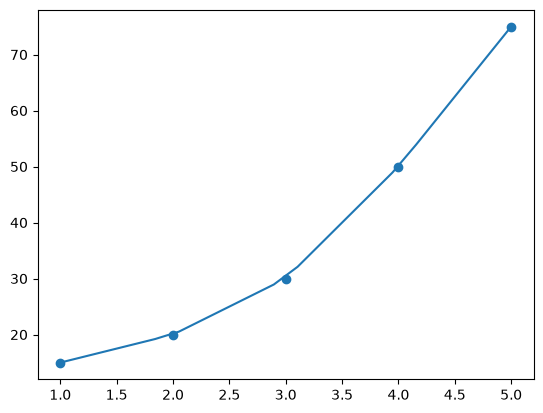

In [8]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([15, 20, 30, 50, 75])

f = interp1d(x, y, kind="linear")

x_new = np.linspace(1, 5, 20)
y_new = f(x_new)

plt.scatter(x, y)
plt.plot(x_new, y_new)
plt.show()

### griddata()

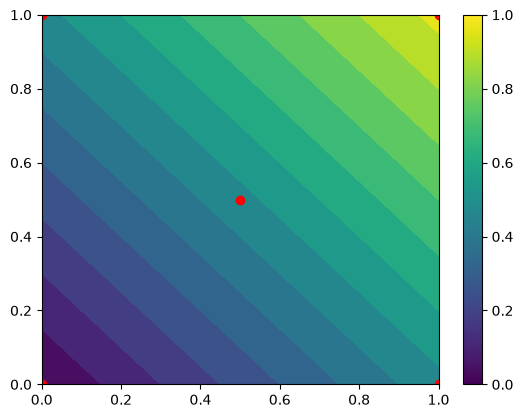

In [9]:
points = np.array([[0, 0], [0, 1], [1, 0], [1, 1], [0.5, 0.5]])
values = np.array([0, 1, 1, 2, 1])

xi, yi = np.mgrid[0:1:30j, 0:1:30j]

zi = griddata(points, values, (xi, yi), method="linear")

plt.contourf(xi, yi, zi, levels=15)
plt.scatter(points[:, 0], points[:, 1], color="red")
plt.colorbar()
plt.show()

---
# 6. Fourier Transform and Signal Processing
### fft()

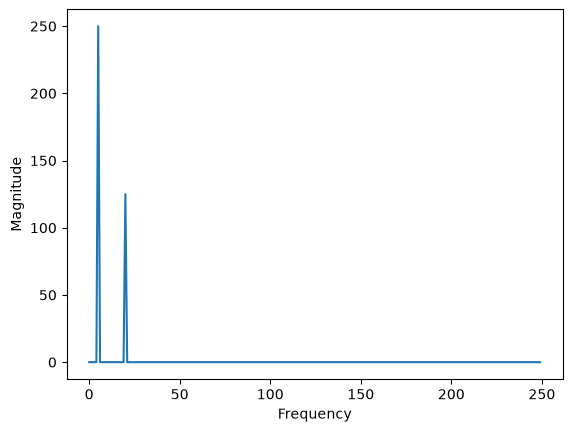

In [10]:
t = np.linspace(0, 1, 500, endpoint=False)
signal = np.sin(2*np.pi*5*t) + 0.5*np.sin(2*np.pi*20*t)

result = fft(signal)
freq = np.fft.fftfreq(len(t), d=t[1]-t[0])

plt.plot(freq[freq >= 0], np.abs(result)[freq >= 0])
plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.show()

### find_peaks()

[16 78]
[1.29128667 1.29738774]


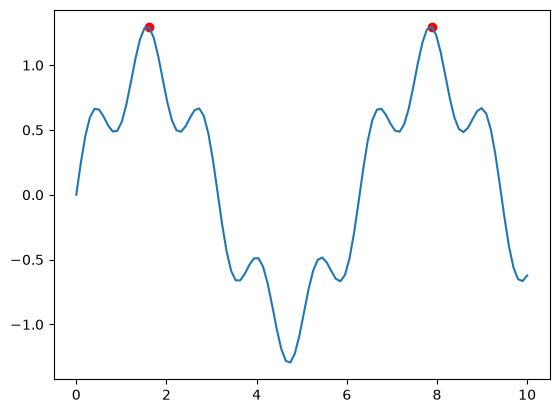

In [11]:
x = np.linspace(0, 10, 100)
y = np.sin(x) + 0.3*np.sin(5*x)

peaks, properties = find_peaks(y, prominence=0.2)

print(peaks)
print(y[peaks])

plt.plot(x, y)
plt.scatter(x[peaks], y[peaks], color="red")
plt.show()

---
# 7. Sparse Matrices (scipy.sparse)

In [12]:
A = np.array([[1, 0, 0],
              [0, 5, 0],
              [0, 0, 9]])

csr = csr_matrix(A)
csc = csc_matrix(A)

print(csr.toarray())
print()
print(csc.toarray())
print()
print(csr.nnz)

[[1 0 0]
 [0 5 0]
 [0 0 9]]

[[1 0 0]
 [0 5 0]
 [0 0 9]]

3


---
# Explanation : 

In [13]:
from IPython.display import IFrame, display

pdf_path = "Explanantion_of_Modules_importing_in_Scipy.pdf"

display(IFrame(pdf_path, width=800, height=500))